# Difference Map
This is a notebook to output difference maps from HGS output salinity data

I am using linear and t_hump for this right, and only the final time step

In [128]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import geopandas as gpd
from scipy.interpolate import griddata

#color lib
import cmocean

In [ ]:
#which timesteps am I using?
timestep = 120
time_index = 4

In [ ]:
#load in data from sims, going to use lse_linear and lse_t_hump for now
#i am unsing the final frame (365 days)
df1 = pd.read_csv(f'../outputs/lse_linear/csv_outputs/salinity_step_00{time_index}.csv') #NOTE: Add a 0 if using a single digit time index
df2 = pd.read_csv(f'../outputs/lse_t_hump/csv_outputs/salinity_step_00{time_index}.csv')

In [131]:
print(df1)

          X    Y       Z  conc_pm.tds  (t = 120)
0     -20.0  0.0 -10.000            1.000000e+00
1     -15.0  0.0 -10.000            9.916280e-01
2     -10.0  0.0 -10.000            9.832165e-01
3      -5.0  0.0 -10.000            9.720166e-01
4       0.0  0.0 -10.000            9.575618e-01
...     ...  ...     ...                     ...
1425  230.0  1.0   1.022            2.865150e-14
1426  235.0  1.0   1.024            1.382642e-16
1427  240.0  1.0   1.026            9.155968e-19
1428  245.0  1.0   1.028            8.048642e-21
1429  250.0  1.0   1.030            0.000000e+00

[1430 rows x 4 columns]


In [132]:
diff = df2[f'conc_pm.tds  (t = {timestep})'] - df1[f'conc_pm.tds  (t = {timestep})']

In [133]:
diff_df = df1.copy()
diff_df[f'conc_pm.tds  (t = {timestep})'] = diff
diff_df = diff_df[['X', 'Z', f'conc_pm.tds  (t = {timestep})']]

In [134]:
diff_df

,X,Z,conc_pm.tds (t = 120)
0,-20.0,-10.000,0.000000e+00
1,-15.0,-10.000,-1.880882e-03
2,-10.0,-10.000,-3.281070e-03
3,-5.0,-10.000,-5.093238e-03
4,0.0,-10.000,-6.586102e-03
...,...,...,...
1425,230.0,1.022,1.153022e-03
1426,235.0,1.024,3.914798e-04
1427,240.0,1.026,1.677270e-05
1428,245.0,1.028,3.611363e-07


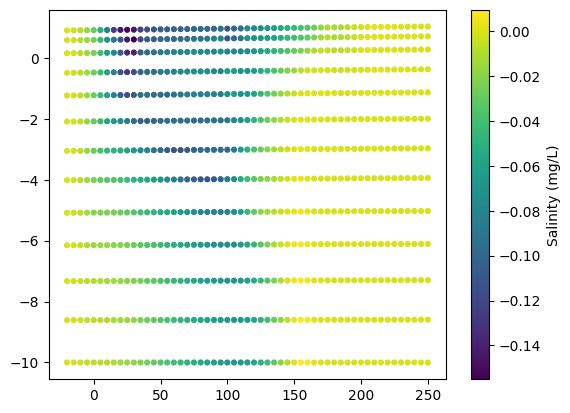

In [135]:
plt.scatter(diff_df['X'], diff_df['Z'], cmap = 'viridis', c = diff_df[f'conc_pm.tds  (t = {timestep})'], s = 10)
#plot color bar
plt.colorbar(label = 'Salinity (mg/L)')

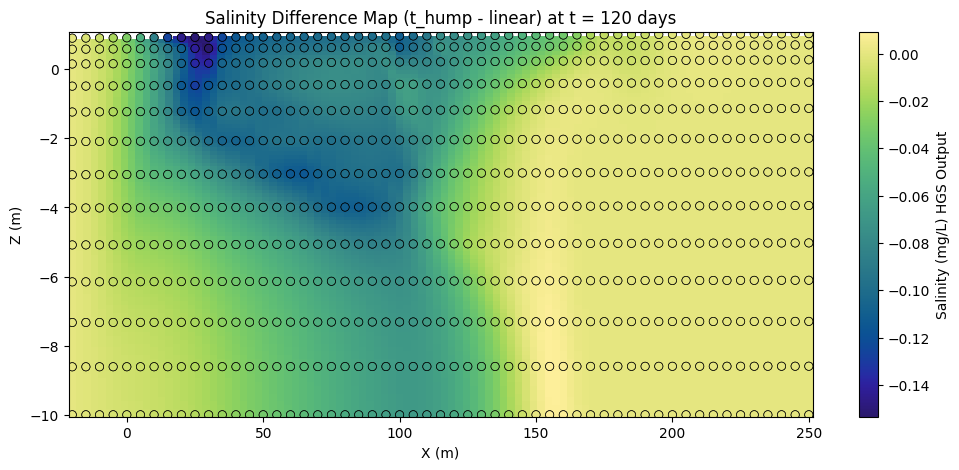

In [136]:
grid_lon, grid_lat = np.meshgrid(
    np.linspace(diff_df['X'].min(), diff_df['X'].max(), 100),
    np.linspace(diff_df['Z'].min(), diff_df['Z'].max(), 100),
)

grid_sal = griddata(
    points = (diff_df['X'], diff_df['Z']),
    values = diff_df[f'conc_pm.tds  (t = {timestep})'],
    xi = (grid_lon, grid_lat),
    method = 'linear',
)

fig, ax = plt.subplots(figsize = (12, 5))

mesh = ax.pcolormesh(
    grid_lon,
    grid_lat,
    grid_sal,
    cmap = cmocean.cm.haline,
    shading = 'auto'
)

#overalying original points on top of the mesh
ax.scatter(
    diff_df['X'],
    diff_df['Z'],
    c = diff_df[f'conc_pm.tds  (t = {timestep})'],
    cmap = cmocean.cm.haline,
    edgecolor = 'k',
    linewidth = 0.5,
    s = 35,
    norm = mesh.norm,
    label = 'Salinity (mg/L) HGS Output'
)

cbar = fig.colorbar(mesh, ax = ax)
cbar.set_label('Salinity (mg/L) HGS Output')
ax.set_xlabel('X (m)')
ax.set_ylabel('Z (m)')
ax.set_title(f'Salinity Difference Map (t_hump - linear) at t = {timestep} days')
#ax.legend(loc = 'upper right')

plt.show()